**24BAD130 Vishal S DL Lab Exp - 02**

COMPARATIVE STUDY OF ACTIVATION FUNCTIONS AND OPTIMIZATION ALGORITHMS IN DEEP LEARNING

 PART A - VISUALIZATION OF ACTIVATION FUNCTIONS

In [1]:
print("24BAD130 Vishal S ")
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('ggplot')

24BAD130 Vishal S 


In [2]:
# Sigmoid Function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Tanh Function
def tanh(x):
    return np.tanh(x)

# ReLU Function
def relu(x):
    return np.maximum(0, x)

In [3]:
x = np.linspace(-10, 10, 500)

24BAD130 Vishal S 


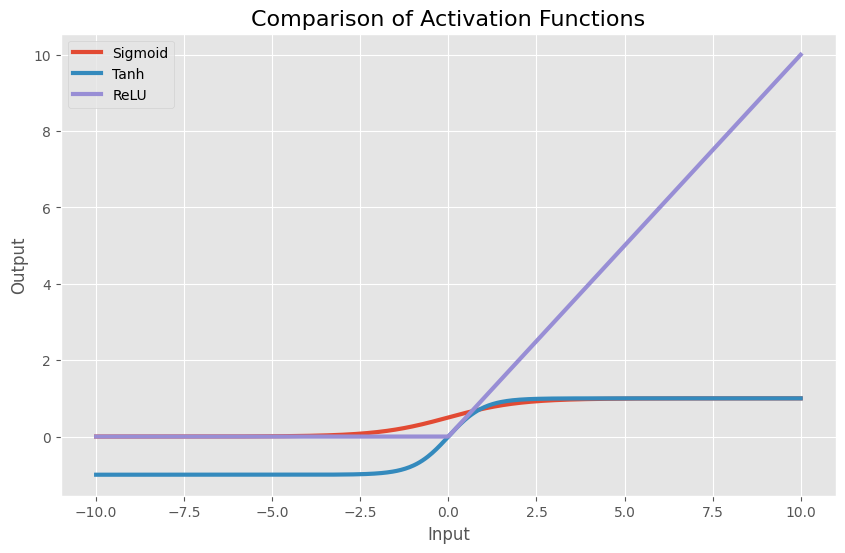

In [4]:
print("24BAD130 Vishal S ")


plt.figure(figsize=(10,6))

plt.plot(x, sigmoid(x), label="Sigmoid", linewidth=3)
plt.plot(x, tanh(x), label="Tanh", linewidth=3)
plt.plot(x, relu(x), label="ReLU", linewidth=3)

plt.title("Comparison of Activation Functions", fontsize=16)
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid(True)

plt.show()

In [5]:
# Derivatives
print("24BAD130 Vishal S ")


def sigmoid_grad(x):
    s = sigmoid(x)
    return s * (1 - s)

def tanh_grad(x):
    return 1 - np.tanh(x)**2

def relu_grad(x):
    return np.where(x > 0, 1, 0)

24BAD130 Vishal S 


24BAD130 Vishal S 


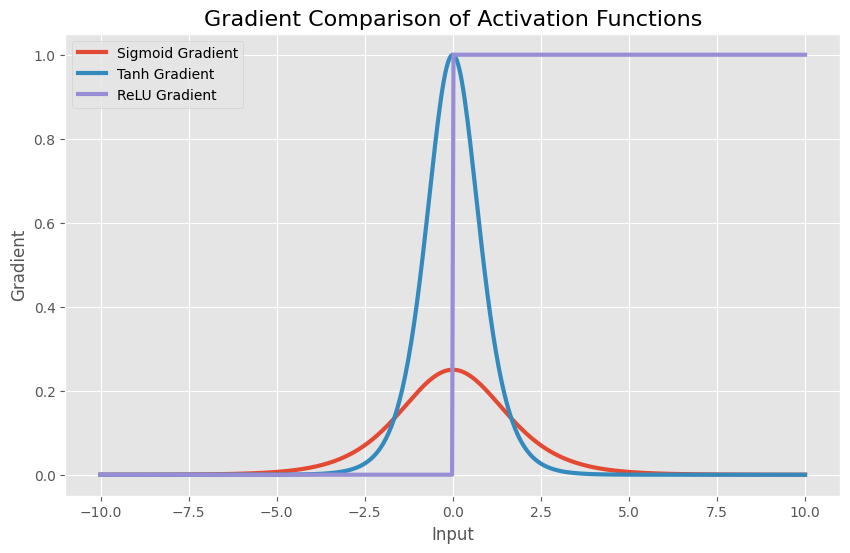

In [6]:
print("24BAD130 Vishal S ")


plt.figure(figsize=(10,6))

plt.plot(x, sigmoid_grad(x), label="Sigmoid Gradient", linewidth=3)
plt.plot(x, tanh_grad(x), label="Tanh Gradient", linewidth=3)
plt.plot(x, relu_grad(x), label="ReLU Gradient", linewidth=3)

plt.title("Gradient Comparison of Activation Functions", fontsize=16)
plt.xlabel("Input")
plt.ylabel("Gradient")
plt.legend()
plt.grid(True)

plt.show()

**24BAD130 Vishal S**

**PART B: PERFORMANCE COMPARISON OF ACTIVATION FUNCTIONS**

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [8]:
# Breast Cancer Dataset

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape :", X.shape)
print("Target Shape :", y.shape)

Dataset Shape : (569, 30)
Target Shape : (569,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [10]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
def build_model(activation):

    model = Sequential([

        Dense(32,
              activation=activation,
              input_shape=(30,)),

        Dense(16,
              activation=activation),

        Dense(1,
              activation='sigmoid')

    ])

    model.compile(

        optimizer='adam',

        loss='binary_crossentropy',

        metrics=['accuracy']

    )

    return model

In [12]:
activations = ['sigmoid', 'tanh', 'relu']

history_dict = {}

for act in activations:

    print("\nTraining with", act)

    model = build_model(act)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_test, y_test),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    history_dict[act] = history


Training with sigmoid


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training with tanh

Training with relu


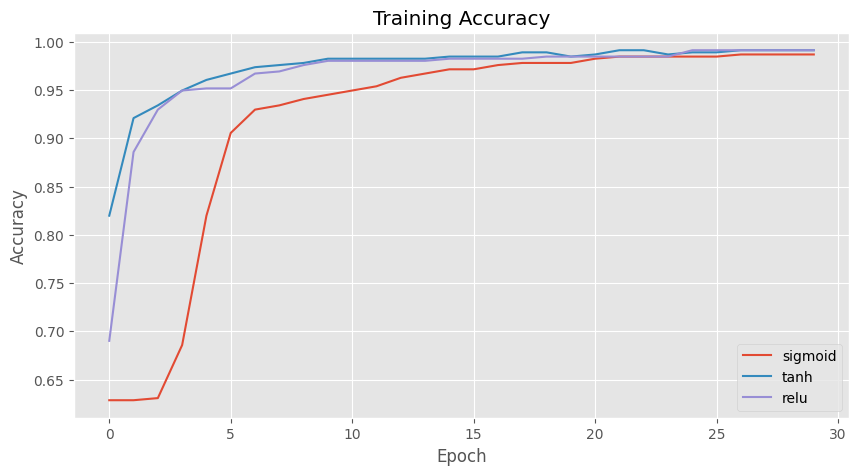

In [13]:
plt.figure(figsize=(10,5))

for act in activations:
    plt.plot(history_dict[act].history['accuracy'], label=act)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

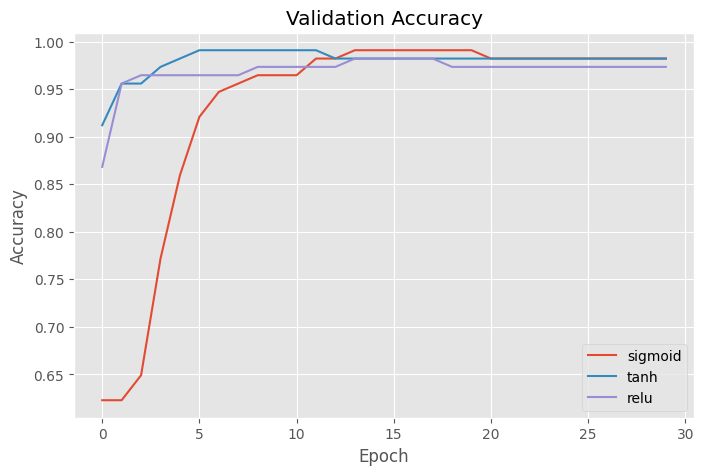

In [16]:
plt.figure(figsize=(8,5))

for act in activations:
    plt.plot(history_dict[act].history['val_accuracy'], label=act)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

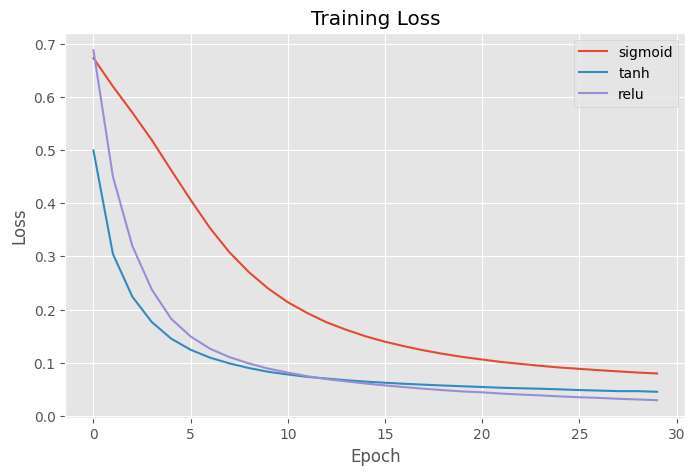

In [19]:
plt.figure(figsize=(8,5))

for act in activations:
    plt.plot(history_dict[act].history['loss'], label=act)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

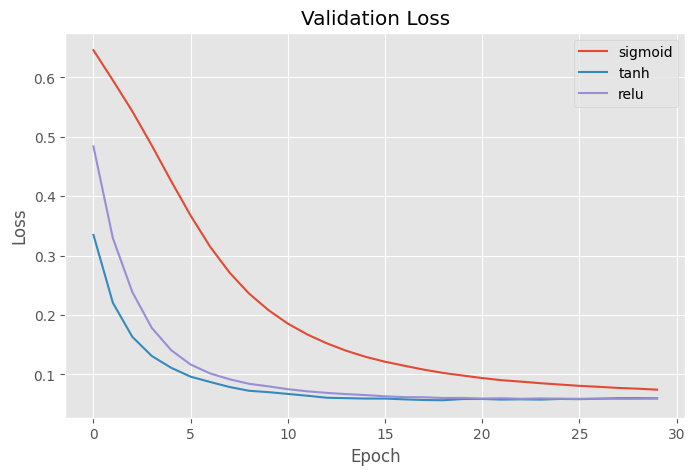

In [21]:
  plt.figure(figsize=(8,5))
for act in activations:
    plt.plot(history_dict[act].history['val_loss'], label=act)

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
print("\n Results")

for act in activations:

    print("\nActivation:", act)

    print("Training Accuracy:",
          round(history_dict[act].history['accuracy'][-1],4))

    print("Validation Accuracy:",
          round(history_dict[act].history['val_accuracy'][-1],4))

    print("Training Loss:",
          round(history_dict[act].history['loss'][-1],4))

    print("Validation Loss:",
          round(history_dict[act].history['val_loss'][-1],4))


 Results

Activation: sigmoid
Training Accuracy: 0.9868
Validation Accuracy: 0.9825
Training Loss: 0.0797
Validation Loss: 0.0744

Activation: tanh
Training Accuracy: 0.9912
Validation Accuracy: 0.9825
Training Loss: 0.0452
Validation Loss: 0.0599

Activation: relu
Training Accuracy: 0.9912
Validation Accuracy: 0.9737
Training Loss: 0.0294
Validation Loss: 0.0595


**24BAD130 Vishal S**

**PART C: COMPARISON OF OPTIMIZATION ALGORITHMS**

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from tensorflow.keras.optimizers import SGD
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.optimizers import Adam

In [25]:
dataset = load_breast_cancer()

X = dataset.data
y = dataset.target

print("Dataset Shape :", X.shape)

Dataset Shape : (569, 30)


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.20,random_state=42)

In [27]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
def create_model(optimizer):

    model = Sequential([

        Dense(32,
              activation='relu',
              input_shape=(30,)),

        Dense(16,
              activation='relu'),

        Dense(1,
              activation='sigmoid')

    ])

    model.compile(

        optimizer=optimizer,

        loss='binary_crossentropy',

        metrics=['accuracy']

    )

    return model

In [29]:
optimizers = {

    "SGD" : SGD(learning_rate=0.01),

    "Momentum" : SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "RMSProp" : RMSprop(),

    "Adam" : Adam()

}

In [30]:
histories = {}

epochs_used = {}

for name, optimizer in optimizers.items():

    print("Training with", name)

    model = create_model(optimizer)

    history = model.fit(

        X_train,y_train,
        validation_data=(X_test, y_test),
        epochs=30,
        batch_size=32,
        verbose=0

    )

    histories[name] = history

    epochs_used[name] = len(history.history['loss'])

print("Training Completed Successfully")

Training with SGD


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training with Momentum
Training with RMSProp
Training with Adam
Training Completed Successfully


In [ ]:
results = []

for name in optimizers.keys():

    history = histories[name]

    results.append({

        "Optimizer":name,

        "Training Loss":
        round(history.history['loss'][-1],4),

        "Validation Loss":
        round(history.history['val_loss'][-1],4),

        "Training Accuracy":
        round(history.history['accuracy'][-1],4),

        "Validation Accuracy":
        round(history.history['val_accuracy'][-1],4),

        "Epochs":
        epochs_used[name]

    })

comparison = pd.DataFrame(results)

comparison

,Optimizer,Training Loss,Validation Loss,Training Accuracy,Validation Accuracy,Epochs
0,SGD,0.1214,0.0980,0.9648,0.9737,30
1,Momentum,0.0283,0.0750,0.9912,0.9737,30
2,RMSProp,0.0264,0.0586,0.9934,0.9737,30
3,Adam,0.0320,0.0956,0.9912,0.9649,30


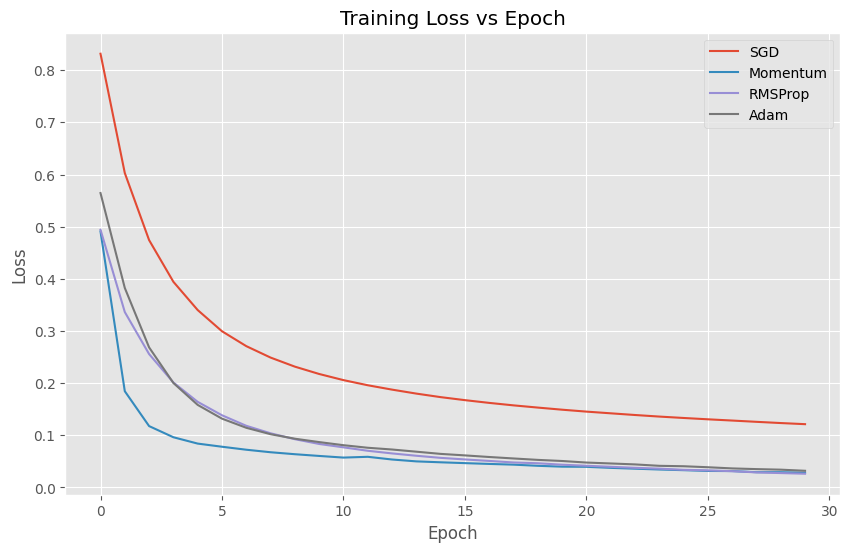

In [ ]:
plt.figure(figsize=(10,6))

for name in optimizers.keys():

    plt.plot(

        histories[name].history['loss'],

        label=name

    )

plt.title("Training Loss vs Epoch")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

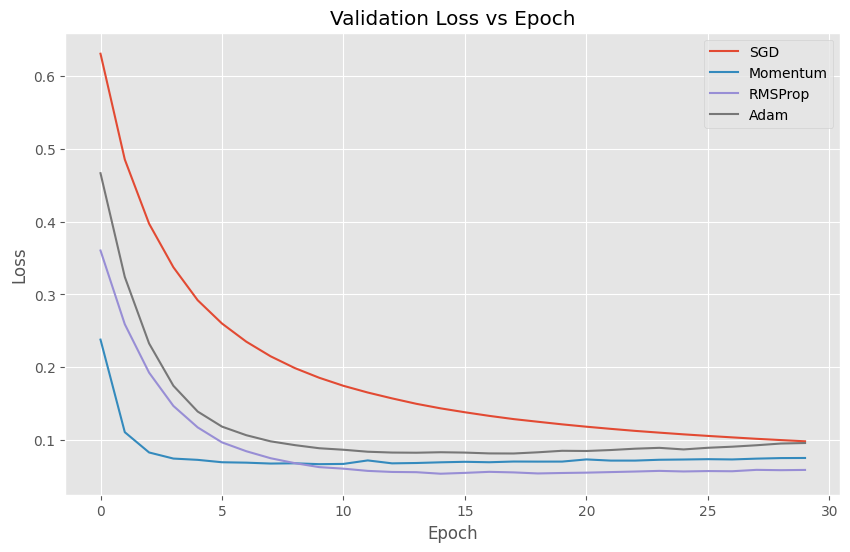

In [ ]:
plt.figure(figsize=(10,6))

for name in optimizers.keys():

    plt.plot(

        histories[name].history['val_loss'],

        label=name

    )

plt.title("Validation Loss vs Epoch")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

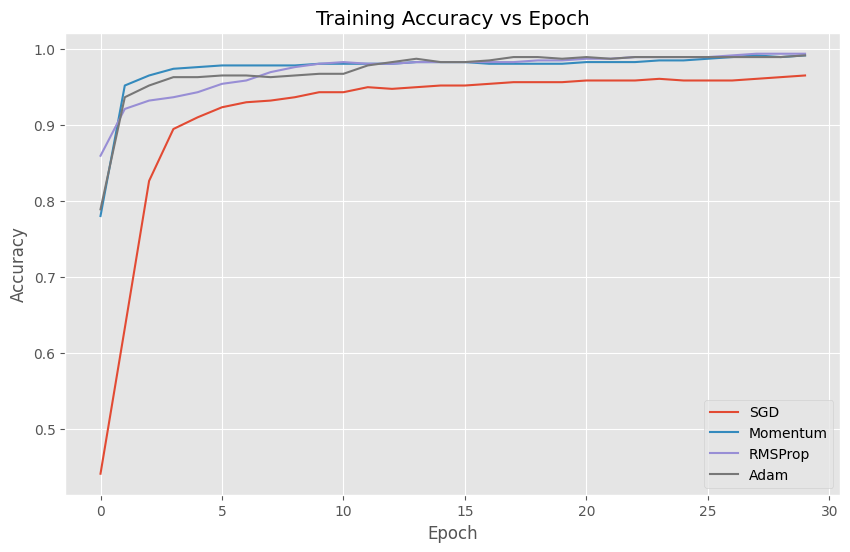

In [ ]:
plt.figure(figsize=(10,6))

for name in optimizers.keys():

    plt.plot(

        histories[name].history['accuracy'],

        label=name

    )

plt.title("Training Accuracy vs Epoch")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

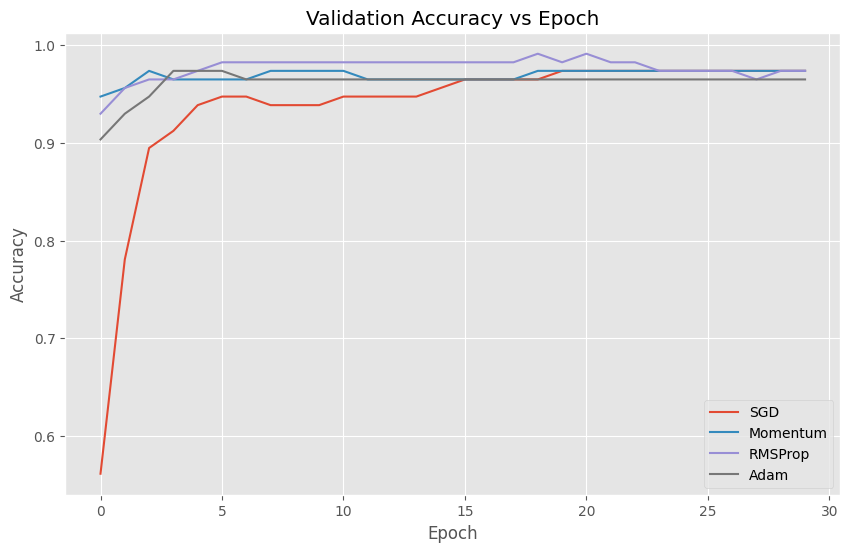

In [ ]:
plt.figure(figsize=(10,6))

for name in optimizers.keys():

    plt.plot(

        histories[name].history['val_accuracy'],

        label=name

    )

plt.title("Validation Accuracy vs Epoch")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

In [32]:
print("\nOptimizer Comparison")

for name in histories:

    print("\nOptimizer:", name)

    print("Training Accuracy:",
          round(histories[name].history['accuracy'][-1], 4))

    print("Validation Accuracy:",
          round(histories[name].history['val_accuracy'][-1], 4))

    print("Training Loss:",
          round(histories[name].history['loss'][-1], 4))

    print("Validation Loss:",
          round(histories[name].history['val_loss'][-1], 4))


Optimizer Comparison

Optimizer: SGD
Training Accuracy: 0.9692
Validation Accuracy: 0.9737
Training Loss: 0.1211
Validation Loss: 0.0948

Optimizer: Momentum
Training Accuracy: 0.9912
Validation Accuracy: 0.9737
Training Loss: 0.0282
Validation Loss: 0.0627

Optimizer: RMSProp
Training Accuracy: 0.9934
Validation Accuracy: 0.9737
Training Loss: 0.0242
Validation Loss: 0.0658

Optimizer: Adam
Training Accuracy: 0.989
Validation Accuracy: 0.9561
Training Loss: 0.0368
Validation Loss: 0.0978


**24BAD130 Vishal S**

**PART D: DEEP LEARNING EXPERIMENT MANAGEMENT**

In [33]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [34]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles in Google Drive:")

!ls /content/drive/MyDrive

Current Working Directory:
/content

Files in Google Drive:
 24BAD130.Marks
'24BAD130 Vishal S Hollestic wellness  02 assignment.pptx'
'24BAD130 Vishal S OOPS Assignment-01.pptx'
'assignment -1.docx'
'Colab Notebooks'
 DL_Lab_Experiment
 ECommerceProject
'Surya Prasad M 24BAD119.gdoc'
'Surya Prasad M 24BAD119.pdf'
'Team 12Design Thinnking Report.docx'
'VISHAL S 24BAD130 EX-2..docx'


In [35]:
project_path = "/content/drive/MyDrive/DL_Lab_Experiment"

os.makedirs(project_path, exist_ok=True)

print("Project Folder Created Successfully")

print(project_path)

Project Folder Created Successfully
/content/drive/MyDrive/DL_Lab_Experiment


In [36]:
with open(project_path + "/Sample.txt","w") as file:

    file.write("Deep Learning Lab\n")
    file.write("Student Name : Vishal S\n")
    file.write("Roll Number : 24BAD130\n")

print("Sample File Saved Successfully")

Sample File Saved Successfully


In [37]:
# Save the trained ANN model

model.save(project_path + "/ANN_Model.keras")

print("ANN Model Saved Successfully")

ANN Model Saved Successfully


In [38]:
model.save(project_path + "/ANN_Model.h5")

In [39]:
!ls "/content/drive/MyDrive/DL_Lab_Experiment"

ANN_Model.h5  ANN_Model.keras  Sample.txt


In [40]:
!git --version

git version 2.34.1


In [41]:
!git config --global user.name "Vishal S"

!git config --global user.email "your_email@gmail.com"

print("Git Configured Successfully")

Git Configured Successfully


In [42]:
!git clone https://github.com/YOUR_USERNAME/Deep-Learning-Lab.git

Cloning into 'Deep-Learning-Lab'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!cp "/content/drive/MyDrive/DL_Lab_Experiment/Sample.txt" \
"/content/Deep-Learning-Lab/"

cp: cannot create regular file '/content/Deep-Learning-Lab/': Not a directory


In [43]:
%cd /content/Deep-Learning-Lab

!git status

[Errno 2] No such file or directory: '/content/Deep-Learning-Lab'
/content
fatal: not a git repository (or any of the parent directories): .git


In [44]:
!git add .

!git commit -m "Added Deep Learning Lab Files"

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [45]:
!git push origin main

fatal: not a git repository (or any of the parent directories): .git


In [46]:
!git push origin master

fatal: not a git repository (or any of the parent directories): .git


In [47]:
readme = """

# Deep Learning Lab

## Experiment

Comparative Study of Activation Functions and Optimization Algorithms

### Student Name

Vishal S

### Roll Number

24BAD130

### Software Used

- Python
- TensorFlow
- Google Colab
- GitHub
- Matplotlib

### Objectives

- Compare Activation Functions

- Compare Optimization Algorithms

- Train ANN Models

- Save Models

- Version Control using GitHub

"""

with open("README.md","w") as file:

    file.write(readme)

print("README Created Successfully")

README Created Successfully


In [48]:
!git add README.md

!git commit -m "Added README File"

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [49]:
!git push origin main

fatal: not a git repository (or any of the parent directories): .git


In [50]:
!cat README.md



# Deep Learning Lab

## Experiment

Comparative Study of Activation Functions and Optimization Algorithms

### Student Name

Vishal S

### Roll Number

24BAD130

### Software Used

- Python
- TensorFlow
- Google Colab
- GitHub
- Matplotlib

### Objectives

- Compare Activation Functions

- Compare Optimization Algorithms

- Train ANN Models

- Save Models

- Version Control using GitHub

